<a href="https://colab.research.google.com/github/vandita1803/DAA-Lab/blob/main/CountNodesinBinaryTree.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:

import time
import statistics

class Node:
    def __init__(self, key):
        self.key = key
        self.left = self.right = None

def count_nodes(root):
    if not root:
        return 0

    l = r = 0
    a, b = root, root

    while a:
        l += 1
        a = a.left

    while b:
        r += 1
        b = b.right

    if l == r:
        return (1 << l) - 1

    return 1 + count_nodes(root.left) + count_nodes(root.right)

def build_tree(n):
    nodes = [Node(i) for i in range(n)]

    for i in range(n):
        if 2*i + 1 < n:
            nodes[i].left = nodes[2*i + 1]
        if 2*i + 2 < n:
            nodes[i].right = nodes[2*i + 2]

    return nodes[0] if nodes else None

sizes = list(range(100, 10001, 500))
times = []
runs = 5
repetitions = 100

for n in sizes:
    root = build_tree(n)
    measurements = []

    for _ in range(runs):
        start = time.perf_counter_ns()

        for _ in range(repetitions):
            count_nodes(root)

        elapsed = time.perf_counter_ns() - start
        measurements.append(elapsed / repetitions)

    times.append(statistics.median(measurements))

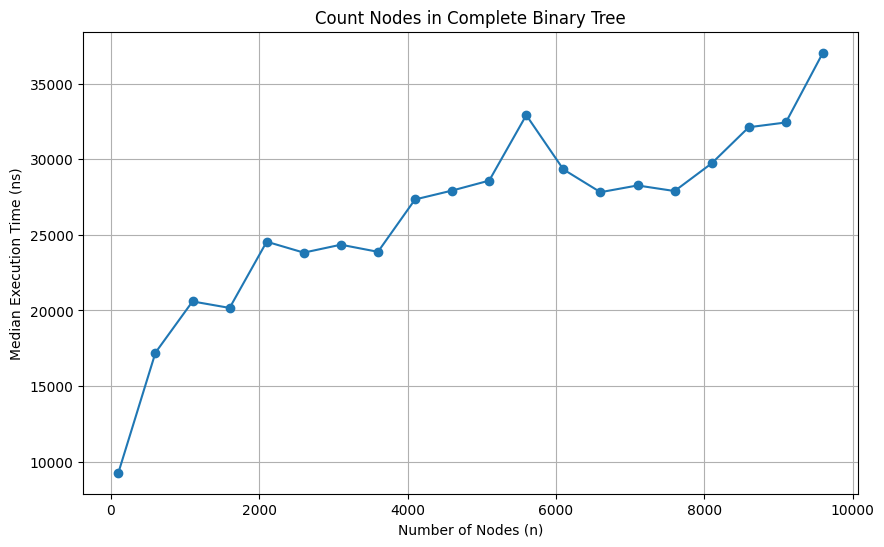

In [ ]:

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
plt.plot(sizes, times, marker='o')
plt.title("Count Nodes in Complete Binary Tree")
plt.xlabel("Number of Nodes (n)")
plt.ylabel("Median Execution Time (ns)")
plt.grid(True)
plt.show()